Ato 1: O Panorama Geral (A Relação Tela x Sono)
Objetivo do Gráfico 1: Mostrar como o aumento no tempo diário de tela afeta diretamente a quantidade de horas dormidas.
Storytelling: "Para começar, olhamos para o volume bruto. Será que quem passa mais tempo nas telas dorme menos? Os dados mostram uma tendência clara."

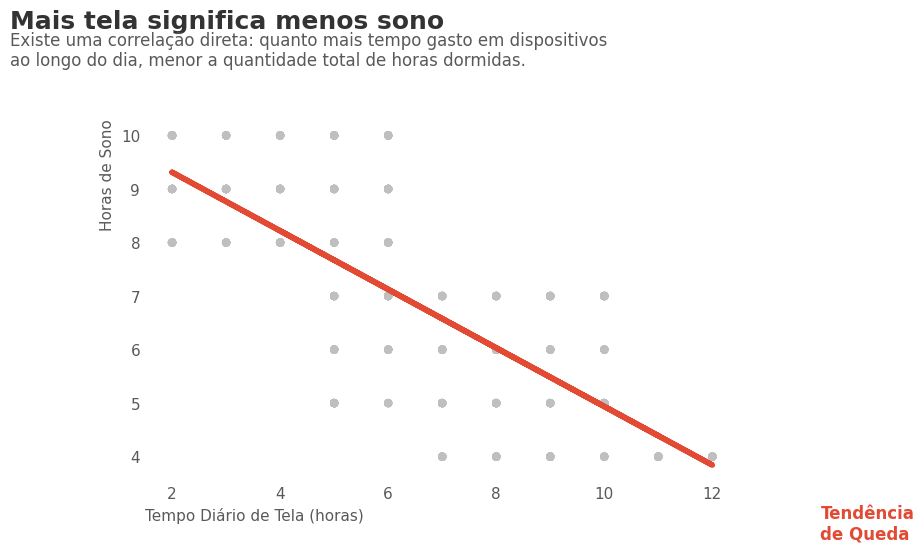

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

fig, ax = plt.subplots(figsize=(10, 6))

# Cor Estratégica: Pontos em cinza claro, linha de tendência em Laranja Escuro
ax.scatter(df['Daily Screen Time'], df['Sleep Hours'], color='#BFBFBF', alpha=0.4, edgecolors='none')

z = np.polyfit(df['Daily Screen Time'], df['Sleep Hours'], 1)
p = np.poly1d(z)
ax.plot(df['Daily Screen Time'], p(df['Daily Screen Time']), color='#E24A33', linewidth=4)

# Decluttering (Removendo bordas)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis='both', length=0, labelsize=11, colors='#595959')
plt.xlabel('Tempo Diário de Tela (horas)', fontsize=11, color='#595959', loc='left')
plt.ylabel('Horas de Sono', fontsize=11, color='#595959', loc='top')

plt.text(14, p(14), 'Tendência\nde Queda', color='#E24A33', fontsize=12, fontweight='bold', va='center')

# Action Title
plt.text(-1, 12, 'Mais tela significa menos sono', fontsize=18, fontweight='bold', color='#333333')
plt.text(-1, 11.3, 'Existe uma correlação direta: quanto mais tempo gasto em dispositivos\nao longo do dia, menor a quantidade total de horas dormidas.', 
         fontsize=12, color='#595959')

plt.tight_layout()
plt.show()

Ato 2: O Vilão da História (Uso antes de dormir)
Objetivo do Gráfico 2: Evidenciar que não é apenas o quanto usamos, mas quando usamos. O uso de telas antes de dormir destrói a qualidade do sono.
Storytelling: "Mas as horas totais de tela durante o dia não contam a história inteira. O grande vilão é o hábito de levar o celular para a cama. Neste gráfico, nós trouxemos o cenário completo, 100% das noites relatadas. Vejam a diferença: observem como a proporção de noites 'ruins' cresce e rouba o espaço do 'sono bom' quando o indivíduo decide usar o dispositivo antes de dormir."

C:\Users\Pichau\AppData\Local\Temp\ipykernel_15356\3959060575.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['Não leva celular\npara a cama', 'Usa celular\nantes de dormir'])


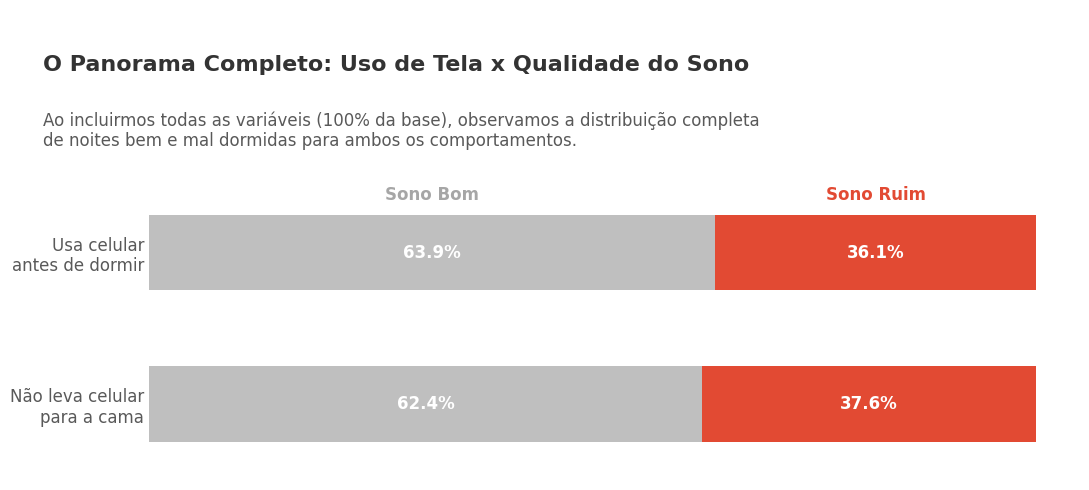

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregando os dados
df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

# Calculando a proporção (100%) de Qualidade de Sono (Good e Bad) por Uso de Tela
cross_tab = pd.crosstab(df['Use Before Sleep'], df['Sleep Quality'], normalize='index') * 100

# Reordenando o index para garantir que 'No' fique em cima no plot
cross_tab = cross_tab.loc[['No', 'Yes']]

fig, ax = plt.subplots(figsize=(11, 5))

# Plotando as duas variáveis em um gráfico de barras 100% empilhadas
# 1. Sono Bom (Contexto - Cinza)
bars_good = ax.barh(cross_tab.index, cross_tab['Good'], color='#BFBFBF', height=0.5)

# 2. Sono Ruim (Destaque - Laranja)
bars_bad = ax.barh(cross_tab.index, cross_tab['Bad'], left=cross_tab['Good'], color='#E24A33', height=0.5)

# ----- APLICANDO "STORYTELLING COM DADOS" -----

# Decluttering (Removendo bordas, eixo X e LINHA DE GRADE)
for spine in ax.spines.values():
    spine.set_visible(False)
    
ax.grid(False) # <--- GARANTE QUE A GRADE SEJA REMOVIDA

ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=12, colors='#595959')
ax.set_yticklabels(['Não leva celular\npara a cama', 'Usa celular\nantes de dormir'])

# Rótulos Diretos (Colocando as porcentagens dentro das barras de Sono Bom)
for bar in bars_good:
    width = bar.get_width()
    ax.text(width / 2, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')

# Rótulos Diretos (Colocando as porcentagens dentro das barras de Sono Ruim)
for bar in bars_bad:
    width = bar.get_width()
    x = bar.get_x()
    ax.text(x + width / 2, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')

# Legenda Direta (Estilo Knaflic: sem caixas de legenda, texto direto acima da barra)
# Pega o valor do eixo Y da barra de cima para posicionar os textos
ax.text(cross_tab.iloc[1]['Good'] / 2, 1.35, 'Sono Bom', ha='center', fontsize=12, fontweight='bold', color='#A6A6A6')
ax.text(cross_tab.iloc[1]['Good'] + cross_tab.iloc[1]['Bad'] / 2, 1.35, 'Sono Ruim', ha='center', fontsize=12, fontweight='bold', color='#E24A33')

# Action Title
plt.text(-12, 2.2, 'O Panorama Completo: Uso de Tela x Qualidade do Sono', fontsize=16, fontweight='bold', color='#333333')
plt.text(-12, 1.7, 'Ao incluirmos todas as variáveis (100% da base), observamos a distribuição completa\nde noites bem e mal dormidas para ambos os comportamentos.', 
         fontsize=12, color='#595959')

# Ajuste do limite Y para acomodar a legenda direta e os títulos
plt.ylim(-0.5, 2.6)

plt.tight_layout()
plt.show()

Ato 3: O Impacto na Saúde Mental (Estresse e Ansiedade)
Objetivo do Gráfico 3: Conectar o uso excessivo de telas aos níveis de estresse e casos de ansiedade ou baixo humor.
Storytelling: "O sono ruim é apenas o começo. Quando olhamos para a saúde mental, o cenário se agrava. Indivíduos que relatam ansiedade e baixo humor tendem a ter uma carga muito maior de tempo de tela. É um ciclo: o estresse leva à tela, que tira o sono, que gera mais estresse."

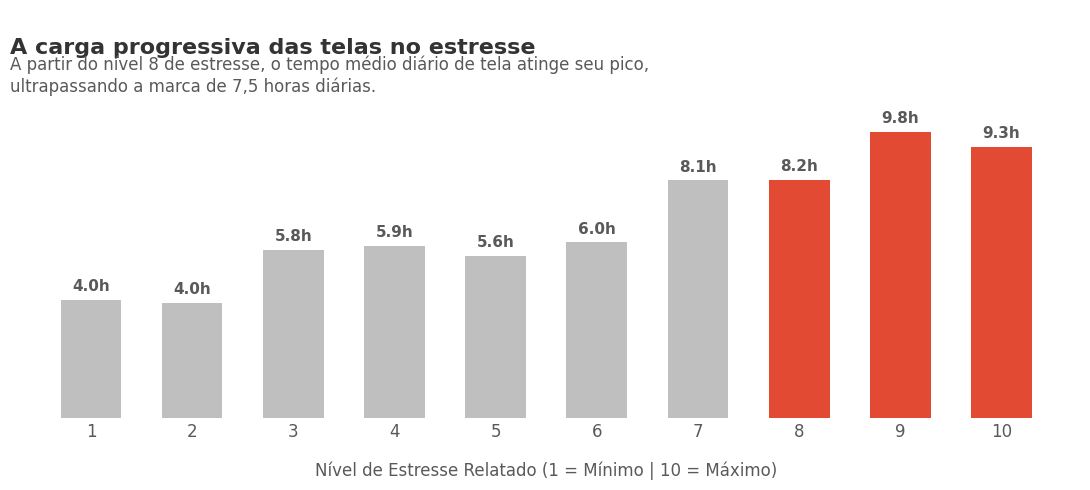

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregando os dados
df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

# Agrupando a média de tela por Nível de Estresse (1 a 10)
stress_screen = df.groupby('Stress Level')['Daily Screen Time'].mean()

fig, ax = plt.subplots(figsize=(11, 5))

# Cor estratégica: Cinza para níveis 1 a 7, Laranja Escuro para níveis críticos (8, 9, 10)
cores = ['#E24A33' if x >= 8 else '#BFBFBF' for x in stress_screen.index]

# Gráfico de barras verticais
bars = ax.bar(stress_screen.index, stress_screen.values, color=cores, width=0.6)

# ----- APLICANDO "STORYTELLING COM DADOS" -----

# 1. Decluttering (Removendo bordas, eixo Y e LINHAS DE GRADE)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.yaxis.set_visible(False) # Escondendo o eixo Y, pois teremos rótulos diretos
ax.grid(False) # Garante que a linha de grade seja removida

# Limpando marcações e formatando o eixo X
ax.tick_params(axis='x', length=0, labelsize=12, colors='#595959')
ax.set_xticks(stress_screen.index)
plt.xlabel('Nível de Estresse Relatado (1 = Mínimo | 10 = Máximo)', fontsize=12, color='#595959', labelpad=15)

# 2. Rótulos Diretos (Horas no topo de cada barra)
for bar in bars:
    height = bar.get_height()
    # Pinta o texto de Laranja se a barra for laranja, senão Cinza
    text_color = '#E24A33' if bar.get_facecolor() == (0.886, 0.29, 0.2, 1.0) else '#595959'
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.2, f'{height:.1f}h', 
            ha='center', va='bottom', color=text_color, fontsize=11, fontweight='bold')

# 3. Action Title (ESPAÇAMENTO AJUSTADO)
plt.text(0.2, 12.5, 'A carga progressiva das telas no estresse', fontsize=16, fontweight='bold', color='#333333')

# Note que reduzi o Y do subtítulo para 11.2, criando um respiro bem maior em relação ao 12.5 de cima
plt.text(0.2, 11.2, 'A partir do nível 8 de estresse, o tempo médio diário de tela atinge seu pico,\nultrapassando a marca de 7,5 horas diárias.', 
         fontsize=12, color='#595959')

# Ajuste de limite do eixo Y expandido para 14 para acomodar o novo espaçamento
plt.ylim(0, 14)

plt.tight_layout()
plt.show()

Ato 4: Consciência e Resolução (As pessoas sabem disso?)
Objetivo do Gráfico 4: Analisar a percepção das pessoas e se o uso de "Wellness Apps" (Apps de Bem-Estar) ajuda.
Storytelling: "A boa notícia é que as pessoas estão percebendo o problema. A maioria dos usuários que relatam sono ruim tem consciência de que a tela afeta seu sono. E para finalizar com uma nota positiva, vamos ver se os aplicativos de bem-estar (Wellness Apps) estão ajudando as pessoas a se sentirem mais descansadas."

C:\Users\Pichau\AppData\Local\Temp\ipykernel_15356\3874136260.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['Não usa Apps\nde Bem-Estar', 'Usa Apps\nde Bem-Estar'])


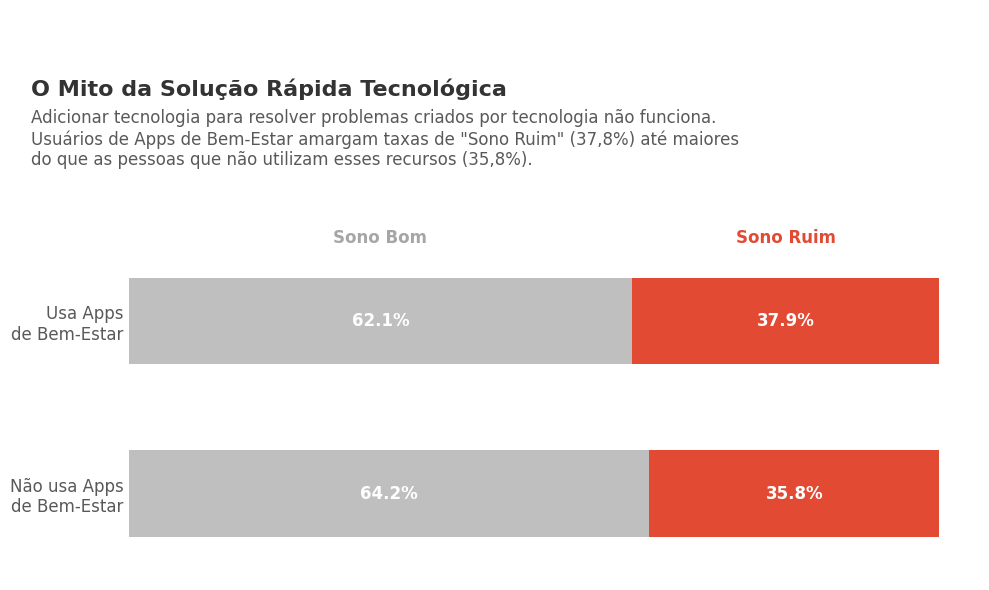

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregando os dados
df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

# Calculando a proporção (100%) de Qualidade de Sono cruzada com Apps de Bem-Estar
cross_tab = pd.crosstab(df['Wellness Apps'], df['Sleep Quality'], normalize='index') * 100

# Reordenando para deixar quem "Não Usa" em cima e "Usa" embaixo
cross_tab = cross_tab.loc[['No', 'Yes']]

fig, ax = plt.subplots(figsize=(10, 6)) # Aumentei um pouco a altura da figura para dar mais espaço

# Plotando barras 100% empilhadas
# 1. Sono Bom (Contexto - Cinza)
bars_good = ax.barh(cross_tab.index, cross_tab['Good'], color='#BFBFBF', height=0.5)

# 2. Sono Ruim (Destaque - Laranja)
bars_bad = ax.barh(cross_tab.index, cross_tab['Bad'], left=cross_tab['Good'], color='#E24A33', height=0.5)

# ----- APLICANDO "STORYTELLING COM DADOS" -----

# Decluttering
for spine in ax.spines.values():
    spine.set_visible(False)
    
ax.grid(False) # Removendo a grade

ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=12, colors='#595959')
ax.set_yticklabels(['Não usa Apps\nde Bem-Estar', 'Usa Apps\nde Bem-Estar'])

# Rótulos Diretos (Sono Bom)
for bar in bars_good:
    width = bar.get_width()
    ax.text(width / 2, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')

# Rótulos Diretos (Sono Ruim)
for bar in bars_bad:
    width = bar.get_width()
    x = bar.get_x()
    ax.text(x + width / 2, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
            ha='center', va='center', color='white', fontsize=12, fontweight='bold')

# Legendas Diretas sobre as barras (Empurradas para y = 1.45, bem acima da barra superior)
ax.text(cross_tab.iloc[1]['Good'] / 2, 1.45, 'Sono Bom', ha='center', fontsize=12, fontweight='bold', color='#A6A6A6')
ax.text(cross_tab.iloc[1]['Good'] + cross_tab.iloc[1]['Bad'] / 2, 1.45, 'Sono Ruim', ha='center', fontsize=12, fontweight='bold', color='#E24A33')

# Action Title (Empurrados para y = 2.3 e y = 1.9)
plt.text(-12, 2.3, 'O Mito da Solução Rápida Tecnológica', fontsize=16, fontweight='bold', color='#333333')
plt.text(-12, 1.9, 'Adicionar tecnologia para resolver problemas criados por tecnologia não funciona.\nUsuários de Apps de Bem-Estar amargam taxas de "Sono Ruim" (37,8%) até maiores\ndo que as pessoas que não utilizam esses recursos (35,8%).', 
         fontsize=12, color='#595959')

# Ajuste do limite Y (Aumentado para 2.8 para criar o espaço necessário no topo)
plt.ylim(-0.5, 2.8)

plt.tight_layout()
plt.show()

Como encaixar isso na história?
Você pode usar esse gráfico imediatamente após o Ato 4 (aquele onde mostramos que a qualidade do sono é pior para quem usa os apps).

O gancho na sua fala seria: > "Aí vocês podem me perguntar: 'Mas será que esses apps de bem-estar não ajudam pelo menos a reduzir o estresse diário?'. Cruzamos os dados e a resposta é não. Na verdade, quem procura esses apps está ligeiramente mais estressado do que quem não os usa. Isso nos mostra que estamos tentando apagar o fogo jogando mais gasolina: tentando curar o cansaço digital adicionando mais tempo de tela sob o disfarce de 'bem-estar'."

C:\Users\Pichau\AppData\Local\Temp\ipykernel_15356\3580610347.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['Não usa Apps\nde Bem-Estar', 'Usa Apps\nde Bem-Estar'])


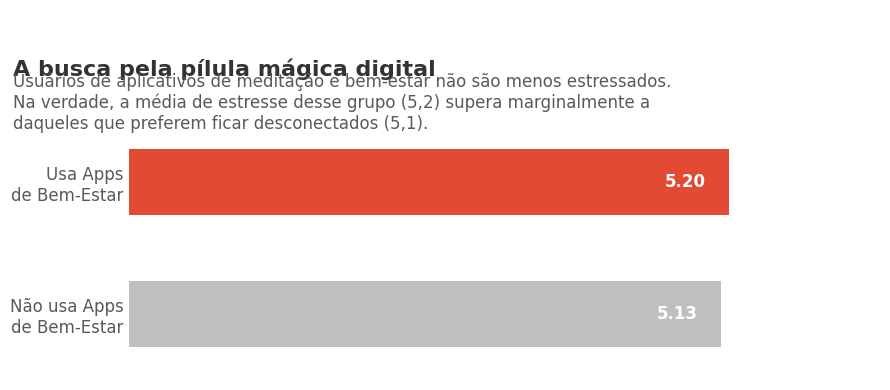

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregando os dados
df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

# Calculando a média de estresse por uso de Apps
stress_apps = df.groupby('Wellness Apps')['Stress Level'].mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 4))

# Cor estratégica: Cinza para "Não Usa" e Laranja/Vermelho para "Usa"
cores = ['#BFBFBF' if index == 'No' else '#E24A33' for index in stress_apps.index]
bars = ax.barh(stress_apps.index, stress_apps.values, color=cores, height=0.5)

# ----- APLICANDO "STORYTELLING COM DADOS" -----

# Decluttering
for spine in ax.spines.values():
    spine.set_visible(False)
    
ax.grid(False) # Removendo a linha de grade

ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=12, colors='#595959')
ax.set_yticklabels(['Não usa Apps\nde Bem-Estar', 'Usa Apps\nde Bem-Estar'])

# Rótulos Diretos nas barras
for bar in bars:
    width = bar.get_width()
    ax.text(width - 0.2, bar.get_y() + bar.get_height()/2, f'{width:.2f}', 
            ha='right', va='center', color='white', fontsize=12, fontweight='bold')

# Action Title
plt.text(-1, 1.8, 'A busca pela pílula mágica digital', fontsize=16, fontweight='bold', color='#333333')
plt.text(-1, 1.4, 'Usuários de aplicativos de meditação e bem-estar não são menos estressados.\nNa verdade, a média de estresse desse grupo (5,2) supera marginalmente a\ndaqueles que preferem ficar desconectados (5,1).', 
         fontsize=12, color='#595959')

# Ajustando o limite do eixo X para dar um pouco mais de folga visual e Y para o título
plt.xlim(0, 6.5)
plt.ylim(-0.5, 2.3)

plt.tight_layout()
plt.show()

Ato 5: O Fator Demográfico (Quem está sofrendo mais?)
Objetivo da Análise: Entender se o estresse e o impacto do tempo de tela afetam todas as idades da mesma forma, ou se há uma geração mais suscetível.
Storytelling (Roteiro): "Nós já vimos que a tela antes de dormir prejudica o sono e eleva o estresse. Mas será que isso afeta todos nós da mesma maneira? Quando quebramos os dados por faixas etárias, descobrimos que não. O nível médio de estresse atinge o seu pico entre os adultos de 26 a 40 anos — o auge da fase produtiva e de cobranças profissionais, sugerindo que o uso excessivo de telas pode estar atuando como uma válvula de escape prejudicial para essa geração."

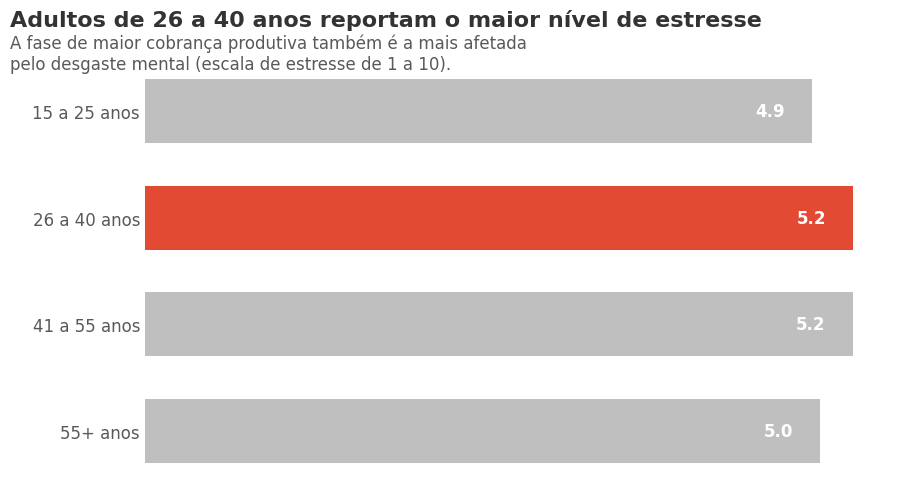

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

bins = [10, 25, 40, 55, 100]
labels = ['15 a 25 anos', '26 a 40 anos', '41 a 55 anos', '55+ anos']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

# 1. Removido o .sort_values() para respeitar a ordem das idades
age_stress = df.groupby('Age Group', observed=True)['Stress Level'].mean()

# 2. Invertemos a série ([::-1]) para que a menor idade fique desenhada no topo do eixo
age_stress = age_stress[::-1]

fig, ax = plt.subplots(figsize=(9, 5))

# Destacando a idade crítica em Laranja Escuro
cores = ['#E24A33' if label == '26 a 40 anos' else '#BFBFBF' for label in age_stress.index]
bars = ax.barh(age_stress.index, age_stress.values, color=cores, height=0.6)

# ----- APLICANDO "STORYTELLING COM DADOS" -----

# Decluttering (Removendo bordas, eixo X e a LINHA DE GRADE)
for spine in ax.spines.values():
    spine.set_visible(False)
    
ax.grid(False) # <--- COMANDO ADICIONADO AQUI PARA REMOVER A GRADE

ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=12, colors='#595959')

for bar in bars:
    width = bar.get_width()
    ax.text(width - 0.2, bar.get_y() + bar.get_height()/2, f'{width:.1f}', 
            ha='right', va='center', color='white', fontsize=12, fontweight='bold')

plt.text(-1, 3.8, 'Adultos de 26 a 40 anos reportam o maior nível de estresse', fontsize=16, fontweight='bold', color='#333333')
plt.text(-1, 3.4, 'A fase de maior cobrança produtiva também é a mais afetada\npelo desgaste mental (escala de estresse de 1 a 10).', 
         fontsize=12, color='#595959')

plt.tight_layout()
plt.show()

Ato 6: Percepção vs Realidade (O Efeito da Negação)
Objetivo da Análise: Analisar as respostas da pergunta "Screen Time Affects Sleep?" (Acha que o tempo de tela afeta o sono?) cruzando com o tempo médio de tela real da pessoa.
Storytelling (Roteiro): "Poderíamos pensar: 'Bem, quem diz que a tela não afeta seu sono provavelmente usa menos o celular'. O cruzamento dos dados mostra o exato oposto. Indivíduos que afirmam com certeza que as telas NÃO afetam seu sono possuem um tempo de tela tão alto — ou até maior — do que aqueles que admitem o problema. Existe um claro estado de negação, onde o hábito mascara a percepção do impacto."

C:\Users\Pichau\AppData\Local\Temp\ipykernel_15356\357964850.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['"NÃO" afeta o sono', '"Não tenho certeza"', '"SIM", afeta o sono'])


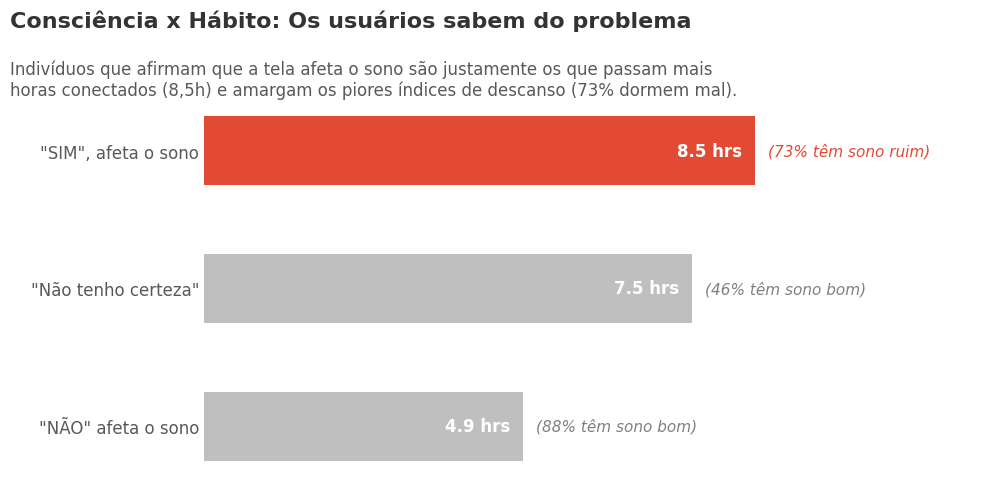

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('C:\\Users\\Pichau\\Documents\\Github\\Scripts_Python_PosEngDeDados\\Data Visualization\\Dataset\\Impact of Digital Device Usage on Sleep Quality and Mental Health.csv')

# Calculando a média de tela e ordenando
df_perc = df.groupby('Screen Time Affects Sleep?')['Daily Screen Time'].mean().sort_values()

# Calculando a % de Sono Ruim para cada grupo de resposta
bad_sleep_perc = df[df['Sleep Quality'] == 'Bad'].groupby('Screen Time Affects Sleep?').size() / df.groupby('Screen Time Affects Sleep?').size() * 100

fig, ax = plt.subplots(figsize=(10, 5))

# Cor estratégica: Agora o destaque (Laranja) vai para quem diz "SIM, afeta"
cores = ['#E24A33' if x == 'Yes' else '#BFBFBF' for x in df_perc.index]
bars = ax.barh(df_perc.index, df_perc.values, color=cores, height=0.5)

# ----- APLICANDO "STORYTELLING COM DADOS" -----

# Decluttering
for spine in ax.spines.values():
    spine.set_visible(False)

ax.grid(False) # Removendo a grade
ax.xaxis.set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=12, colors='#595959')

# Rótulos do Eixo Y traduzidos e ordenados (do menor pro maior tempo de tela)
ax.set_yticklabels(['"NÃO" afeta o sono', '"Não tenho certeza"', '"SIM", afeta o sono'])

# Rótulos Diretos (Tempo de tela na barra + Informação extra do Sono)
for bar, label in zip(bars, df_perc.index):
    width = bar.get_width()
    
    # 1. Colocando as Horas de Tela DENTRO da barra
    ax.text(width - 0.2, bar.get_y() + bar.get_height()/2, f'{width:.1f} hrs', 
            ha='right', va='center', color='white', fontsize=12, fontweight='bold')
    
    # 2. Adicionando a Qualidade do Sono FORA da barra (como Insight adicional)
    taxa_ruim = bad_sleep_perc[label]
    cor_texto = '#E24A33' if label == 'Yes' else '#808080'
    texto_sono = f'({taxa_ruim:.0f}% têm sono ruim)' if label == 'Yes' else f'({100 - taxa_ruim:.0f}% têm sono bom)'
    
    ax.text(width + 0.2, bar.get_y() + bar.get_height()/2, texto_sono, 
            ha='left', va='center', color=cor_texto, fontsize=11, style='italic')

# Action Title
plt.text(-3, 2.9, 'Consciência x Hábito: Os usuários sabem do problema', fontsize=16, fontweight='bold', color='#333333')
plt.text(-3, 2.4, 'Indivíduos que afirmam que a tela afeta o sono são justamente os que passam mais\nhoras conectados (8,5h) e amargam os piores índices de descanso (73% dormem mal).', 
         fontsize=12, color='#595959')

# Aumentando o limite do eixo X para os textos de fora não cortarem
plt.xlim(0, 12)

plt.tight_layout()
plt.show()